# 00 · Evoked responses masquerade as oscillations

Toy examples used in the poster's **Introduction**:

1. Three transient peaks — no oscillation at all — convolved with Morlet wavelets produce low-frequency power that overlaps the theta band.
2. Regressing the ERP out of each trial *before* time-frequency decomposition removes that evoked smear and keeps the genuine (induced) 8 Hz oscillation. This only works because the ERP here is perfectly time-locked across trials — the assumption that latency jitter breaks (notebook `01`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

fs = 500                      # Hz
t = np.arange(0, 2.0, 1 / fs) # s
freqs = np.linspace(1, 40, 80)


def make_erp(t, t0, sigma, amp):
    """Gaussian 'ERP' peaking at t0 with width sigma (s)."""
    return amp * np.exp(-0.5 * ((t - t0) / sigma) ** 2)


def morlet_power(x, freqs, fs, n_cycles=6):
    """Power of a 1-D signal convolved with unit-area, 6-cycle Morlet wavelets."""
    power = np.zeros((len(freqs), len(x)))
    for fi, freq in enumerate(freqs):
        sigma_t = n_cycles / (2 * np.pi * freq)
        half_win = int(4 * sigma_t * fs)
        t_wav = np.arange(-half_win, half_win + 1) / fs
        wavelet = (np.exp(-t_wav**2 / (2 * sigma_t**2)) * np.exp(2j * np.pi * freq * t_wav)
                   / (sigma_t * np.sqrt(2 * np.pi)))
        power[fi] = np.abs(np.convolve(x, wavelet, mode='same')[:len(x)]) ** 2
    return power


def plot_power(power, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(power, aspect='auto', origin='lower',
                   extent=[t[0], t[-1], freqs[0], freqs[-1]],
                   cmap='hot', vmin=0, vmax=np.percentile(power, 98))
    plt.colorbar(im, ax=ax, label='Power (a.u.)')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_stacked(signals, title, offset):
    colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(signals)))
    fig, ax = plt.subplots(figsize=(6, 5))
    for i, (sig, color) in enumerate(zip(signals, colors)):
        ax.plot(t, sig + i * offset, lw=2, color=color)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude + offset (µV)')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 1. Transient peaks produce spurious low-frequency power

Three Gaussian peaks, from wide and early (σ = 120 ms) to narrow and late (σ = 15 ms).

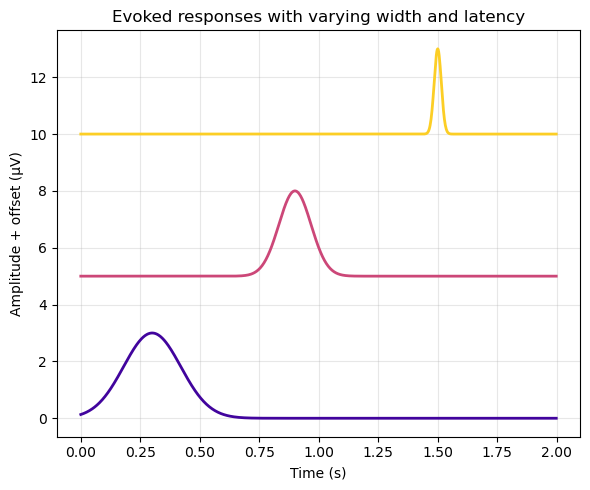

In [2]:
sigmas = np.linspace(0.120, 0.015, 3)  # 120 ms -> 15 ms
t0s = np.linspace(0.3, 1.5, 3)          # early -> late
erps = np.array([make_erp(t, t0, sigma, amp=3.0) for t0, sigma in zip(t0s, sigmas)])

plot_stacked(erps, 'Evoked responses with varying width and latency', offset=5)

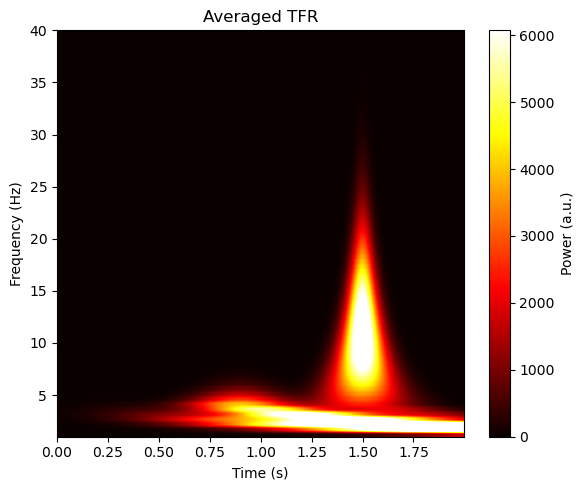

In [3]:
tfr_avg = np.mean([morlet_power(erp, freqs, fs) for erp in erps], axis=0)
plot_power(tfr_avg, 'Averaged TFR')

## 2. Regressing out a perfectly time-locked ERP

Three trials, each containing the same ERP plus an 8 Hz oscillation with random phase and white noise. The ERP is regressed out of every trial (`trial = β·ERP + ε`, keep ε) before computing power.

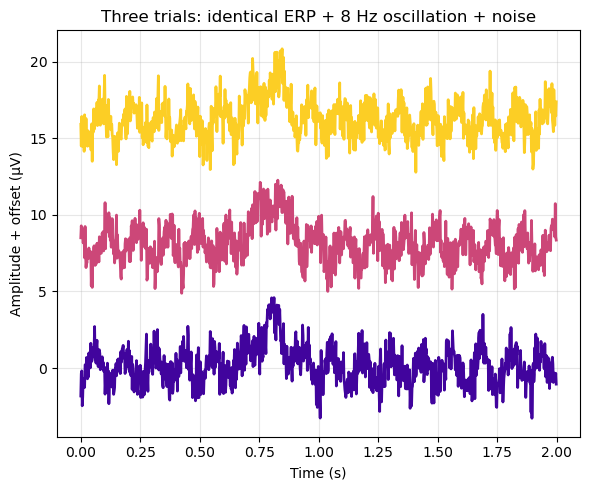

In [4]:
erp = make_erp(t, t0=0.8, sigma=0.06, amp=3.0)
osc_freq, osc_amp, noise_level = 8, 1.0, 0.8

trials = np.array([
    erp
    + osc_amp * np.sin(2 * np.pi * osc_freq * t + rng.uniform(0, 2 * np.pi))
    + noise_level * rng.standard_normal(len(t))
    for _ in range(3)
])

plot_stacked(trials, 'Three trials: identical ERP + 8 Hz oscillation + noise', offset=8)

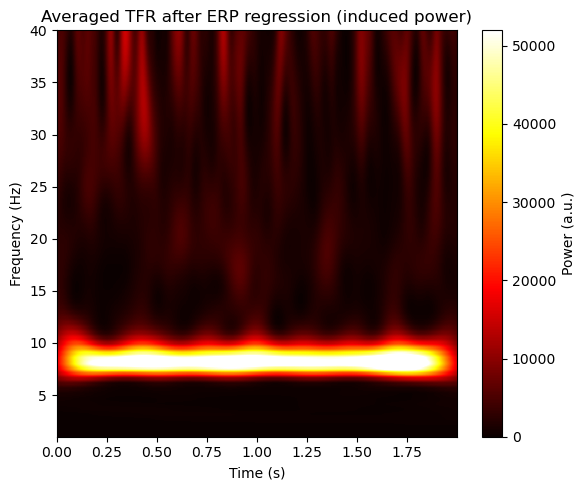

In [5]:
betas = trials @ erp / (erp @ erp)
trials_induced = trials - betas[:, None] * erp[None, :]

tfr_induced = np.mean([morlet_power(tr, freqs, fs) for tr in trials_induced], axis=0)
plot_power(tfr_induced, 'Averaged TFR after ERP regression (induced power)')